# 01. Готовность данных к сравнению моделей

Проверяем сохранность строк, меток и временной карты, покрытие кандидатных
признаков. Обучение, заполнение пропусков и выбор модели не выполняются.
Принимаем временную карту погодного этапа: train до 2022, validation 2022,
test 2023 по C40 UTC. Старый вариант sample-selection с зазором не подменяет
эту карту; расхождение необходимо решить до обучения.

`airport` предполагается известным из внешнего плана полета. Геометрия C40
и метаданные имеют ретроспективное происхождение; историческое время их
получения не подтверждено. Проверка полноты не доказывает доступность.
Семантика `C40_BEARING` и словарь `AC_CLASS` требуют отдельного решения.
Исходы посадки, число попыток, ILS и посадочная полоса не входят в предикторы.


In [1]:
from pathlib import Path
import hashlib, json
from collections import Counter
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
OUT=ROOT/'research/weather-model-comparison'
for name in ['reports','figures']: (OUT/name).mkdir(parents=True,exist_ok=True)
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''): h.update(chunk)
    return h.hexdigest()
source=ROOT/'europe/data/analytical/06_05_cases_excluded.parquet'
source_hash=sha(source)
assert source_hash=='1111c7480ff7615042a332c586c8f60459bf5d6000da11ea4d0ec2a773fc0719'
N=6331485
source_labels=np.empty(N,dtype=bool)
source_times=np.empty(N,dtype='datetime64[ns]')
source_airports=np.empty(N,dtype=object)
fields=['airport','C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON','typecode','icaoaircrafttype','AC_CLASS']
counts=Counter(); missing=Counter(); ranges={}; offset=0
for batch in pq.ParquetFile(source).iter_batches(batch_size=200000,columns=fields+['GoA','C40_CROSS_TIME']):
    f=batch.to_pandas(); n=len(f)
    times=pd.to_datetime(f.C40_CROSS_TIME,utc=True)
    assert times.notna().all()
    parts=np.where(times.dt.year<2022,'train',np.where(times.dt.year==2022,'validation','test'))
    assert times.dt.year.between(2019,2023).all()
    source_labels[offset:offset+n]=f.GoA.to_numpy(dtype=bool)
    source_times[offset:offset+n]=times.dt.tz_localize(None).to_numpy()
    source_airports[offset:offset+n]=f.airport.to_numpy()
    for part in ['train','validation','test']:
        selected=f.loc[parts==part]
        counts[part]+=len(selected)
        for field in fields:
            empty=selected[field].isna()
            if field in ['airport','typecode','icaoaircrafttype','AC_CLASS']:
                empty=empty|selected[field].eq('')
            missing[(part,field)]+=int(empty.sum())
    for field in ['C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON']:
        values=pd.to_numeric(f[field],errors='coerce'); finite=values[np.isfinite(values)]
        old=ranges.get(field,[float('inf'),float('-inf'),0])
        ranges[field]=[min(old[0],float(finite.min())),max(old[1],float(finite.max())),old[2]+int((values.notna()&~np.isfinite(values)).sum())]
    offset+=n
assert offset==N and source_labels.sum()==18349
assert dict(counts)=={'train':4165060,'validation':1619848,'test':546577}
base=pd.DataFrame([{'temporal_split':p,'field':field,'rows':counts[p],'missing':missing[(p,field)],'missing_percent':100*missing[(p,field)]/counts[p]} for p in counts for field in fields])
base.to_csv(OUT/'reports/01_nonweather_missingness.csv',index=False)
display(base)
display(pd.DataFrame(ranges,index=['minimum','maximum','nonfinite']).T)


,temporal_split,field,rows,missing,missing_percent
0,train,airport,4165060,0,0.000000
1,train,C40_BEARING,4165060,0,0.000000
2,train,C40_CROSS_LAT,4165060,0,0.000000
3,train,C40_CROSS_LON,4165060,0,0.000000
4,train,typecode,4165060,130945,3.143892
5,train,icaoaircrafttype,4165060,165858,3.982128
6,train,AC_CLASS,4165060,0,0.000000
7,validation,airport,1619848,0,0.000000
8,validation,C40_BEARING,1619848,0,0.000000
9,validation,C40_CROSS_LAT,1619848,0,0.000000


,minimum,maximum,nonfinite
C40_BEARING,0.000000,359.988163,0.0
C40_CROSS_LAT,39.805278,60.319722,0.0
C40_CROSS_LON,-7.393611,22.058889,0.0


## 2. Связь погоды и временной карты

Удаляем старый заполнитель `temporal_split` и присоединяем карту по
`source_row` с проверкой one-to-one. Для каждой строки сверяем аэропорт,
метку и время C40 с исходным массивом. Проверяем отсутствие повторов
между файлами и полный охват исходных позиций. Погодные признаки берем
только из принятых копий `_model`; отсутствие порывов и облачного потолка
не интерпретируется автоматически как ошибка или нулевое значение.


In [2]:
weather=ROOT/'europe/weather/data/final_c40_weather_v1'
mapping=ROOT/'europe/weather/data/temporal_split_v1'
manifest=json.loads((ROOT/'europe/weather/reports/24_temporal_split_application.json').read_text(encoding='utf8'))
assert manifest['source_input_sha256']==source_hash
map_hashes={x['name']:x['sha256'] for x in manifest['files']}
seen=np.zeros(N,dtype=bool); records=[]; file_checks=[]
for path in sorted(weather.glob('*.parquet')):
    schema=pq.read_schema(path).names
    model_fields=[x for x in schema if x.endswith('_model')]
    f=pd.read_parquet(path,columns=['source_row','C40_CROSS_TIME','airport','GoA','temporal_split','weather_core_usable']+model_fields)
    mp=mapping/path.name
    assert sha(mp)==map_hashes[path.name]
    m=pd.read_parquet(mp)
    joined=f.drop(columns='temporal_split').merge(m[['source_row','temporal_split']],on='source_row',how='left',validate='one_to_one')
    assert len(joined)==len(f) and joined.temporal_split.notna().all()
    ids=joined.source_row.to_numpy(dtype=np.int64)
    assert ((ids>=0)&(ids<N)).all() and not seen[ids].any()
    assert np.array_equal(joined.GoA.to_numpy(),source_labels[ids])
    assert np.array_equal(joined.airport.to_numpy(),source_airports[ids])
    time=pd.to_datetime(joined.C40_CROSS_TIME,utc=True)
    assert np.array_equal(time.dt.tz_localize(None).to_numpy(),source_times[ids])
    mm=m.set_index('source_row').loc[ids]
    assert np.array_equal(mm.GoA.to_numpy(),source_labels[ids])
    assert np.array_equal(mm.airport.to_numpy(),source_airports[ids])
    assert np.array_equal(pd.to_datetime(mm.C40_CROSS_TIME,utc=True).dt.tz_localize(None).to_numpy(),source_times[ids])
    expected=np.where(time.dt.year<2022,'train',np.where(time.dt.year==2022,'validation','test'))
    assert np.array_equal(joined.temporal_split.to_numpy(),expected)
    seen[ids]=True
    for (part,airport,label),group in joined.groupby(['temporal_split','airport','GoA']):
        for field in model_fields:
            records.append({'temporal_split':part,'airport':airport,'GoA':bool(label),'field':field,'rows':len(group),'missing':int(group[field].isna().sum()),'weather_usable':int(group.weather_core_usable.sum())})
    file_checks.append({'file':path.name,'rows':len(joined),'weather_sha256':sha(path),'mapping_sha256':map_hashes[path.name]})
assert seen.all() and len(file_checks)==93
coverage=pd.DataFrame(records)
coverage.to_csv(OUT/'reports/01_weather_missingness_by_airport.csv',index=False)
summary=coverage.groupby(['temporal_split','field'],as_index=False)[['rows','missing']].sum()
summary['missing_percent']=100*summary.missing/summary.rows
summary.to_csv(OUT/'reports/01_weather_missingness.csv',index=False)
display(summary.pivot(index='field',columns='temporal_split',values='missing_percent').round(3))
result={'verified':True,'rows':N,'GoA':int(source_labels.sum()),'source_input_sha256':source_hash,'split_rows':dict(counts),'files':file_checks,'training_executed':False,'source_row_complete_and_unique':True,'source_labels_times_airports_equal':True}
(OUT/'reports/01_readiness_manifest.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf8')


temporal_split,test,train,validation
field,,,
cavok_model,0.099,0.149,0.132
cloud_amount_unavailable_model,0.099,0.149,0.132
cloud_ceiling_ft_model,58.289,64.698,72.373
cloud_ceiling_relation_model,0.099,0.149,0.132
cloud_ceiling_status_model,0.099,0.149,0.132
cloud_type_unavailable_model,0.099,0.149,0.132
cumulonimbus_reported_model,0.099,0.149,0.132
dewpoint_c_model,0.100,0.152,0.135
gust_group_reported_model,0.099,0.149,0.132


23828

## 3. Полнота признаков по временным частям

Каждая доля пропусков использует все строки соответствующей части.
Данные не фильтруются по наличию погоды. Для категорий в непогодном блоке
пустая строка учтена как отсутствие значения; преобразование данных не выполнялось.


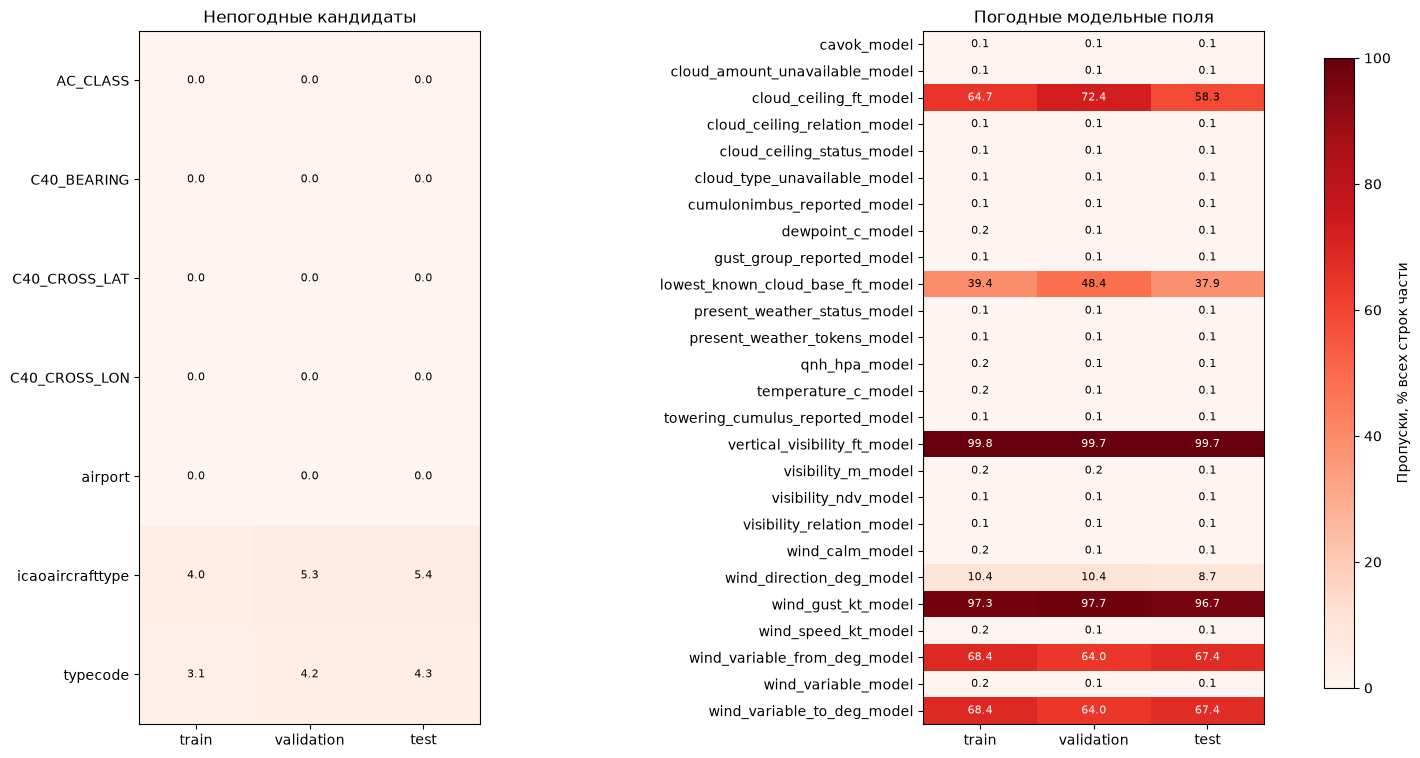

In [3]:
fig,axes=plt.subplots(1,2,figsize=(15,9))
for ax,frame,title in [(axes[0],base,'Непогодные кандидаты'),(axes[1],summary,'Погодные модельные поля')]:
    matrix=frame.pivot(index='field',columns='temporal_split',values='missing_percent')[['train','validation','test']]
    im=ax.imshow(matrix.to_numpy(),vmin=0,vmax=100,cmap='Reds',aspect='auto')
    ax.set_yticks(range(len(matrix)),matrix.index); ax.set_xticks(range(3),matrix.columns)
    ax.set_title(title)
    for y in range(len(matrix)):
        for x in range(3):
            value=matrix.iloc[y,x]
            ax.text(x,y,f'{value:.1f}',ha='center',va='center',fontsize=8,color='white' if value>60 else 'black')
fig.subplots_adjust(left=.12,right=.87,wspace=1.3)
cax=fig.add_axes([.91,.15,.02,.7])
fig.colorbar(im,cax=cax,label='Пропуски, % всех строк части')
for ext in ['png','svg']: fig.savefig(OUT/f'figures/01_feature_missingness.{ext}',dpi=160,bbox_inches='tight')
plt.show()


## 4. Следующие решения

Проверки связи и полноты не являются разрешением на обучение.
До него необходимо согласовать:

1. Единый вариант временных границ: принятая карта всех строк либо отдельно
   документированная чувствительность с зазором и исключением пересекающих границу исходов.
2. Допуск геометрии C40 и метаданных при отсутствии исторического received_at;
   bearing и AC_CLASS до уточнения семантики не включать автоматически.
3. Наборы погодных полей, использование давности, COR и индикаторов пропусков.
   Признаки источника и доступности могут отражать особенности наблюдения.
4. Семейство моделей, обучение преобразований только на train, метрики,
   порог на validation и одинаковые строки обеих моделей. Test уже просматривался.

Исходные значения, метки и готовые погодные таблицы не изменены.
